# Lab 6 · A hidden planet weighed by its pull: Kepler-88

Kepler-88 b transits its star every 10.95 days, but not on time: its transits come up to half a day early or
late. Nothing else transits. The culprit is a second planet, c, on an orbit just outside the 2:1 resonance; each
time the two line up they tug on each other, and the tugs add up into a slow wave in the transit times. The size
of the wave weighs the hidden planet. Here: 119 transit times of b measured from Kepler data by Holczer et al. (2016).

In [1]:
import io
import os
import urllib.request
import numpy as np
import esl
import esl.plot

DATA = os.environ.get("ESL_DATA", "https://pearsonkyle.github.io/Exoplanet-Science-Lab/examples/")
fetch = lambda path: urllib.request.urlopen(DATA + path).read().decode()

d = np.genfromtxt(io.StringIO(fetch("kepler88/transit_times.csv")), delimiter=",", names=True, dtype=None, encoding="utf-8")
n, t, e = d["epoch"], d["tmid"], d["err"]
print(f"{t.size} transit times over {(t.max() - t.min()) / 365.25:.1f} years; median error {1440 * np.median(e):.1f} min")

119 transit times over 4.0 years; median error 2.0 min


## 1. A steady clock would give a flat O − C

In [2]:
lin = esl.fit_ephemeris(t, e, epochs=n)
print(lin)

Linear ephemeris from 119 times
  T0 = 2454954.676596 +- 0.000253 BJD_TDB
  P  = 10.95311372 +- 0.00000329 d
  chi2 = 5927710.8 for 117 degrees of freedom (reduced 50664.19), BIC = 5927720.3
  reduced chi2 well above 1: the error bars are too small for this model, or the times vary in another way


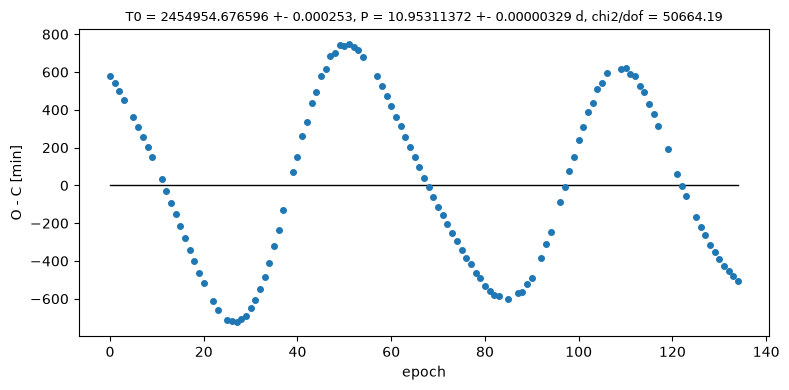

In [3]:
esl.plot.ephemeris(lin, t, e);

Far from flat: the transits swing by about ±12 hours. χ² per point is enormous for a straight line.

## 2. How long is the wave?

The periodogram of the residuals finds the period of the timing variation, the **super-period**. For two planets
near a j : j−1 resonance it is 1 / |j/P_c − (j−1)/P_b|, which says roughly where planet c must be.

In [4]:
pg = esl.periodogram(t, e, epochs=n)
print(pg)

The strongest peak in the O − C periodogram is at 56.4 epochs (618 d), with a false-alarm probability of 3 × 10^-79: significant at the 1% level. A sinusoid there has amplitude 642.30 ± 0.27 min. The BIC prefers the 2-sinusoid model over the linear ephemeris by 5875857.9 (very strong evidence), and over one sinusoid by 160072.4. Both signals pass both tests (second peak: 30.2 epochs, false-alarm probability 2 × 10^-30).
  Linear ephemeris   chi2 = 5927710.8  BIC = 5927720.3
  1 sinusoid         chi2 = 211910.9  BIC = 211934.8  [period 56.86 epochs = 622.8 d, amplitude 642.3 min]
  2 sinusoids        chi2 = 51824.2  BIC = 51862.4  [period 57.32 epochs = 627.8 d, amplitude 650.4 min]  [period 30.20 epochs = 330.8 d, amplitude 105.3 min]
  note: The preferred model still has a reduced chi-square of 466.9: the error bars may be too small, which inflates every BIC difference here.
  note: The scatter left after the 2 sinusoids model is larger than the error bars allow (reduced chi-square 46

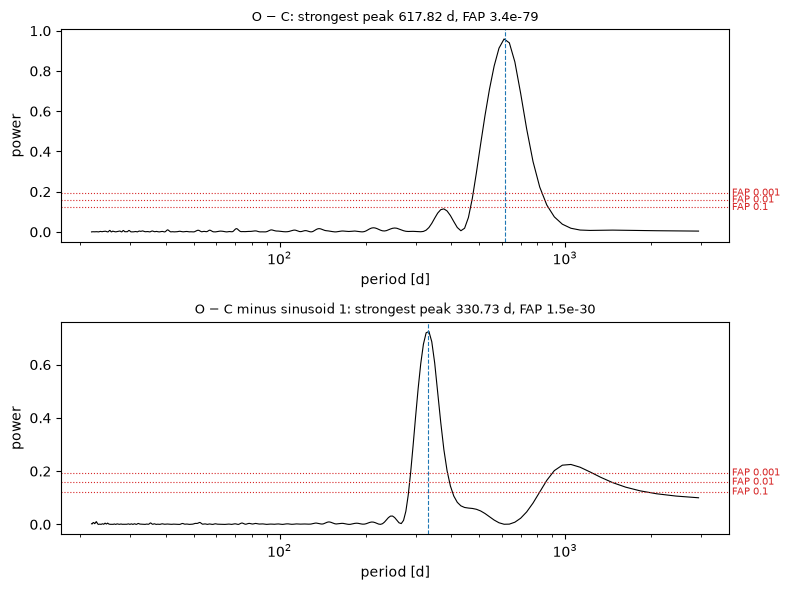

In [5]:
esl.plot.periodogram(pg);

## 3. The N-body fit

A model with two planets that pull on each other (an N-body integration, not two Kepler orbits) is fitted to the
times: the mass, period and phase of c and both eccentricities. That takes many minutes; the website's worked
example stores the result, which we open here. To run it yourself: `fit = session.run(progress=True)`.

In [6]:
session = esl.Session.model_validate_json(fetch("results/kepler88.json"))
r = session.result
print(r.table())

converged: 943766 calls, 1938.6 s, ln Z = 404.605 +- 0.350, chi2 = 110.17 for 119 measurements
  mplanet@c  0.6706 +0.0062 -0.0058  M Jup
  per@c      22.33488 +0.00070 -0.00072  d
  tmid@c     2454949.78 +0.13 -0.11  d
  secosw     -0.23579 +0.00091 -0.00058
  sesinw     -0.011 +0.015 -0.013
  secosw@c   0.2387 +0.0013 -0.0015
  sesinw@c   0.008 +0.016 -0.018
  derived:
  rpJup      0.3072555
  t14        0.14444432
  emid       2454959.8
  ars        23.058206
  b          0.40232184
  K          2.7679916
  mplanet    0.03
  rpJup@c    0.087288494
  t14@c      0
  emid@c     2454961.76 +0.12 -0.11
  ars@c      37.09138 +0.00073 -0.00076
  b@c        1.930291 +0.000038 -0.000039
  K@c        48.74 +0.43 -0.43


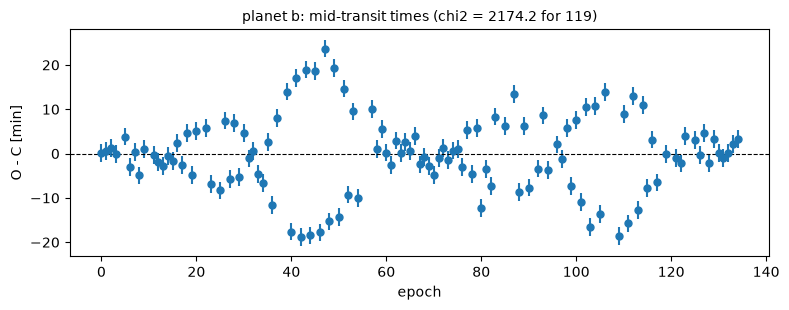

In [7]:
esl.plot.oc(session);

## 4. Compare with the radial velocities measured years later

Weiss et al. (2020) measured the star's velocity with Keck: Mc = 0.674 ± 0.016 M_Jup. Timing alone found it.

In [8]:
key = next(k for k in ["mplanet@c", "mplanet"] if k in r)
m = r[key]
print(f"timing alone: Mc = {m.median:.3f} +{m.plus:.3f} -{m.minus:.3f} M_Jup;  Weiss et al. 2020: 0.674 +- 0.016  ({(m.median - 0.674) / np.hypot(m.plus, 0.016):+.1f} sigma)")

timing alone: Mc = 0.671 +0.006 -0.006 M_Jup;  Weiss et al. 2020: 0.674 +- 0.016  (-0.2 sigma)
